# WP11 · Kayıtlı A1P1 protein/PPI graf açıklaması

**Uygulama aşaması; WP11 nihai kapanışı değildir.** Kayıtlı WP10 dış modelleri sabittir. Yeni eğitim, optimizer veya sonuçlara göre yöntem araması yoktur. B1 SHAP dosyaları korunmuştur. Buradaki tekil mesaj maskeleme duyarlılığı **SHAP değildir**; katkıların toplamı bütün protein/PPI etkisini vermek zorunda değildir.

Araştırılan büyüklük `Δz=z_orijinal−z_müdahale`dır. Pozitif değer ilgili mesajın kaldırılmasıyla modelin observed-record logitinin düştüğünü; negatif değer arttığını gösterir. Bu klinik risk değişimi veya biyolojik nedensellik değildir. SIDER unknown çiftleri doğrulanmış negatif değildir.

## 1. Sonuç öncesi sözleşme ve sentetik kapı

Birincil işlem orijinal degree/rol sayısı ve availability maskesini sabit tutar. PPI çiftinin iki yönlü mesajı birlikte maskelenir. Ayrı duyarlılıkta gerçek edge/rol ilişkisi silinir, kalan degree/rol sayısı yeniden hesaplanır; son rol ilişkisi silinirse rol maskesi de kapanır. Kimya/atom dalları sabittir. Mevcut olmayan yol NA'dır.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP11/graph_v1';F=ROOT/'reports/figures/WP11/graph_v1';F.mkdir(parents=True,exist_ok=True)
policy=json.loads((Q/'policy_v1.json').read_text(encoding='utf-8'))
complete=json.loads((Q/'analysis_complete.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{k:policy[k] for k in ['status','primary','sensitivity','output','examples']}]).T)
print((Q/'synthetic_tests_before_real.txt').read_text(encoding='utf-8'))


test_01_fixed_vs_renormalized_PPI (test_wp11_graph_synthetic.AnalyticGraphTests.test_01_fixed_vs_renormalized_PPI) ... ok
test_02_zero_intervention_equals_reference_encoder (test_wp11_graph_synthetic.AnalyticGraphTests.test_02_zero_intervention_equals_reference_encoder) ... ok
test_03_role_count_and_last_mask (test_wp11_graph_synthetic.AnalyticGraphTests.test_03_role_count_and_last_mask) ... ok
test_04_zero_role_intervention_matches_reference (test_wp11_graph_synthetic.AnalyticGraphTests.test_04_zero_role_intervention_matches_reference) ... ok
test_05_query_cache_and_other_drug_isolation (test_wp11_graph_synthetic.AnalyticGraphTests.test_05_query_cache_and_other_drug_isolation) ... ok
test_06_protein_index_permutation (test_wp11_graph_synthetic.AnalyticGraphTests.test_06_protein_index_permutation) ... ok
test_07_ID_and_role_alignment (test_wp11_graph_synthetic.AnalyticGraphTests.test_07_ID_and_role_alignment) ... ok
test_08_repeat_and_source_immutable (test_wp11_graph_synthetic.Analyti

,0
status,FROZEN_BEFORE_SYNTHETIC_AND_REAL_ATTRIBUTION
primary,single message masked to0;original degree or role count AND availability masks fixed
sensitivity,physical undirected PPI pair/typed role relation deletion;remaining degree/count recomputed;last...
output,delta_z=original_logit-intervened_logit;signed;not SHAP;not additive decomposition;not clinical ...
examples,each context first2 lexicographic eligible test drug IDs plus DB00199 Erythromycin if heldout;fi...


**Yorum:** Gerçek attribution başlamadan 10 analitik test geçti. İlgili zaman/hash kapısı saklandı. Sözleşme test veya katkı sonucuna göre değiştirilmedi. İlk gerçek deneme hash yardımcısına yanlış nesne türü verildiği için katkı üretmeden durdu; hata ve boş dosyalar arşivlendi. Düzeltme yalnız bu teknik denetim çağrısıydı.

### Mean aggregation neden iki farklı sonuç verir?

In [2]:

from wp09_encoder import distinguishing_fixture
from wp11_graph_forward import protein_messages,torch
m,x,pairs=distinguishing_fixture()
with torch.no_grad():
    proof=[]
    for label,ei,mode in [('Orijinal',None,'fixed'),('A–B sabit derece maskesi',0,'fixed'),('A–B silme / yeni derece',0,'delete')]:
        out=protein_messages(m,x,pairs,ei,mode)
        proof.append({'analitik_sentetik_durum':label,'B_degree':float(out['degree'][1]),'B_neighbor_mean':out['mean'][1].tolist(),'B_temsili':out['h'][1].tolist()})
display(pd.DataFrame(proof))


,analitik_sentetik_durum,B_degree,B_neighbor_mean,B_temsili
0,Orijinal,2.0,"[1.5, 3.0]","[7.5, 5.0]"
1,A–B sabit derece maskesi,2.0,"[1.0, 2.0]","[7.0, 4.0]"
2,A–B silme / yeni derece,1.0,"[2.0, 4.0]","[8.0, 6.0]"


**Analitik örnek:** A–B–C zincirinde B'ye gelen C mesajı sabit paydada C/2, silme sonrası C/1'dir. B temsilleri sırasıyla [7,4] ve [8,6] olur. Bu elle belirlenmiş küçük test gerçek ilaç sonucu olarak sunulmaz. Gerçek tablolar aşağıdadır.

## 2. Gerçek kapsam: envanter, input ve hesap yolu

,envanter,skor,protein_rolü,PPI_yolu
protocol,,,,
primary,62,61,60,51
stress,62,61,60,51


,context,drug_id,name,eligible,chemistry_available,atom_QC_available,role_relations,PPI_status
3,primary_o01_final,DB00479,Amikacin,True,True,True,1,NA_no_path
12,primary_o01_final,DB06590,Ceftaroline fosamil,True,True,True,7,NA_no_path
19,primary_o02_final,DB00919,Spectinomycin,True,True,True,1,NA_no_path
24,primary_o02_final,DB01172,Kanamycin,True,True,True,4,NA_no_path
25,primary_o02_final,DB01416,Cefpodoxime,True,True,True,1,NA_no_path
27,primary_o03_final,DB00259,Sulfanilamide,True,True,True,1,NA_no_path
37,primary_o03_final,DB06799,Methenamine,False,False,False,0,NA_no_path
40,primary_o04_final,DB00560,Tigecycline,True,True,True,5,NA_no_path
41,primary_o04_final,DB00684,Tobramycin,True,True,True,0,NA_no_path
46,primary_o04_final,DB01150,Cefprozil,True,False,False,3,NA_no_path


,protocol,PPI_path_status,rol_bağlantısı
0,primary,NA_no_incident_train_PPI,182
1,primary,NA_unseen_self_only,85
2,primary,present,209
3,stress,NA_no_incident_train_PPI,178
4,stress,NA_unseen_self_only,89
5,stress,present,209


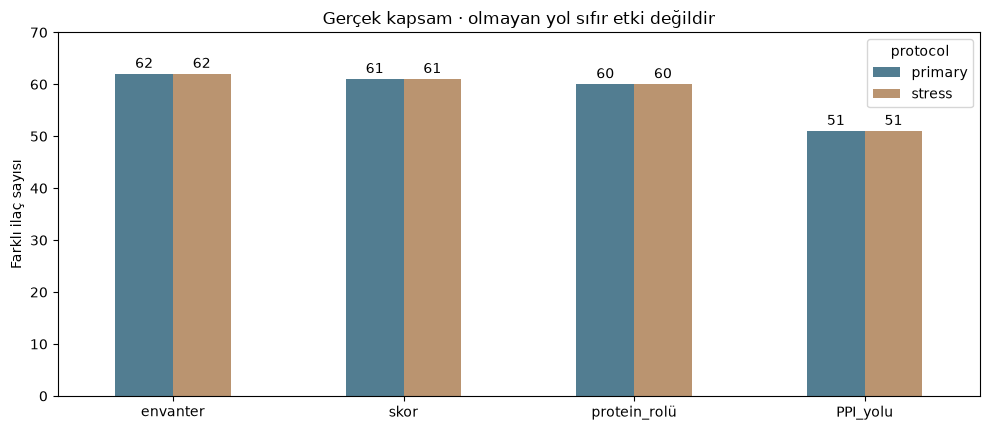

,context,reference_logit_error,original_cache_error,OOF_score_error,OOF_pairs_checked,role_interventions,PPI_query_interventions,repeat_error,other_query_role_isolation_error,delete_NA_interventions,model_graph_query_cache_unchanged
0,primary_o01_final,0.0,0.0,1.110223e-16,3120,122,406,0.0,0.0,0,True
1,primary_o02_final,0.0,0.0,5.960464e-08,3718,99,284,0.0,0.0,0,True
2,primary_o03_final,0.0,0.0,2.980232e-08,3498,78,397,0.0,0.0,0,True
3,primary_o04_final,0.0,0.0,5.960464e-08,3756,80,158,0.0,0.0,0,True
4,primary_o05_final,0.0,0.0,1.490116e-08,3912,97,378,0.0,0.0,0,True
5,stress_o01_final,0.0,0.0,2.980232e-08,3822,117,333,0.0,0.0,0,True
6,stress_o02_final,0.0,0.0,1.110223e-16,3952,120,330,0.0,0.0,0,True
7,stress_o03_final,0.0,0.0,1.490116e-08,3912,71,228,0.0,0.0,0,True
8,stress_o04_final,0.0,0.0,1.110223e-16,3344,77,286,0.0,0.0,0,True
9,stress_o05_final,0.0,0.0,2.980232e-08,2940,91,427,0.0,0.0,0,True


,context,class_id,status
654,primary_o03_final,C0027497,NA_not_fitted
2810,stress_o05_final,C0027497,NA_not_fitted


In [3]:

coverage=pd.read_csv(Q/'drug_coverage.csv');paths=pd.read_csv(Q/'protein_path_coverage.csv');absent=pd.read_csv(Q/'absent_paths_NA.csv')
scope=coverage.groupby('protocol').agg(envanter=('drug_id','size'),skor=('eligible','sum'),protein_rolü=('role_relations',lambda v:(v>0).sum()),PPI_yolu=('applicable_PPI_pairs',lambda v:(v>0).sum()))
display(scope)
named_scope=pd.read_csv(Q/'all_drug_scope_named.csv')
display(named_scope[named_scope.applicable_PPI_pairs.eq(0)][['context','drug_id','name','eligible','chemistry_available','atom_QC_available','role_relations','PPI_status']])
display(paths.groupby(['protocol','PPI_path_status']).size().rename('rol_bağlantısı').reset_index())
fig,ax=plt.subplots(figsize=(10,4.4));scope.T.plot.bar(ax=ax,color=['#527d91','#ba9470'],rot=0)
ax.set(ylabel='Farklı ilaç sayısı',title='Gerçek kapsam · olmayan yol sıfır etki değildir',ylim=(0,70))
for container in ax.containers:ax.bar_label(container,padding=2)
plt.tight_layout();plt.savefig(F/'01_real_path_coverage.png',dpi=160);plt.show()
display(pd.read_csv(Q/'consistency_checks.csv'))
display(pd.read_csv(Q/'target_scope.csv').query("status=='NA_not_fitted'"))


**Grafik 1 — Ne öğrendik?** Her protokolde 62 envanter / 61 skor / 60 protein rolü / 51 PPI-yollu ilaç var. Methenamine abstain; Tobramycin protein rolü olmadan mevcut diğer girdileriyle korunur. Train dışında kalan query proteinleri self-only'dir; bunlar için yeni PPI komşuluğu eklenmedi. İnsan PPI kenarları strict aynı-taxID STRING700'dür; diğer organizmaların proteinleri envanterde bulunabilse de E.coli K12 ağı veya context80 eklenmedi.

35.974 orijinal ilaç–PT logiti yeniden üretildi. Yeni açıklama forward'ı kabul edilmiş encoder ile sıfır müdahalede tam eşleşti; önceki OOF sigmoid skorundan en büyük fark yaklaşık 5,96×10⁻⁸ (float32 işlem yolu sınırı). Modeller ve önceki OOF dosyaları değiştirilmedi.

## 3. Local gerçek örnekler: Doxycycline ve Erythromycin

Örnekler alfabetik ilk test kimlikleri ve önceden belirtilen Erythromycin'dir; ilk iki fit edilmiş CUI kullanılır. Ağlar primary outer1 ilk örneği ile Erythromycin'in gerçek heldout folduna aittir. Başarılı tahmin veya büyük attribution seçimi yapılmamıştır.

,context,protocol,outer_fold,drug_id,class_id,selection
0,primary_o01_final,primary,1,DB00254,C0000731,lexicographic plus predeclared Erythromycin;no outcome or performance
1,primary_o01_final,primary,1,DB00254,C0000737,lexicographic plus predeclared Erythromycin;no outcome or performance
2,primary_o01_final,primary,1,DB00438,C0000731,lexicographic plus predeclared Erythromycin;no outcome or performance
3,primary_o01_final,primary,1,DB00438,C0000737,lexicographic plus predeclared Erythromycin;no outcome or performance
4,primary_o02_final,primary,2,DB00207,C0000731,lexicographic plus predeclared Erythromycin;no outcome or performance
5,primary_o02_final,primary,2,DB00207,C0000737,lexicographic plus predeclared Erythromycin;no outcome or performance
6,primary_o02_final,primary,2,DB00415,C0000731,lexicographic plus predeclared Erythromycin;no outcome or performance
7,primary_o02_final,primary,2,DB00415,C0000737,lexicographic plus predeclared Erythromycin;no outcome or performance
8,primary_o03_final,primary,3,DB00199,C0000731,lexicographic plus predeclared Erythromycin;no outcome or performance
9,primary_o03_final,primary,3,DB00199,C0000737,lexicographic plus predeclared Erythromycin;no outcome or performance


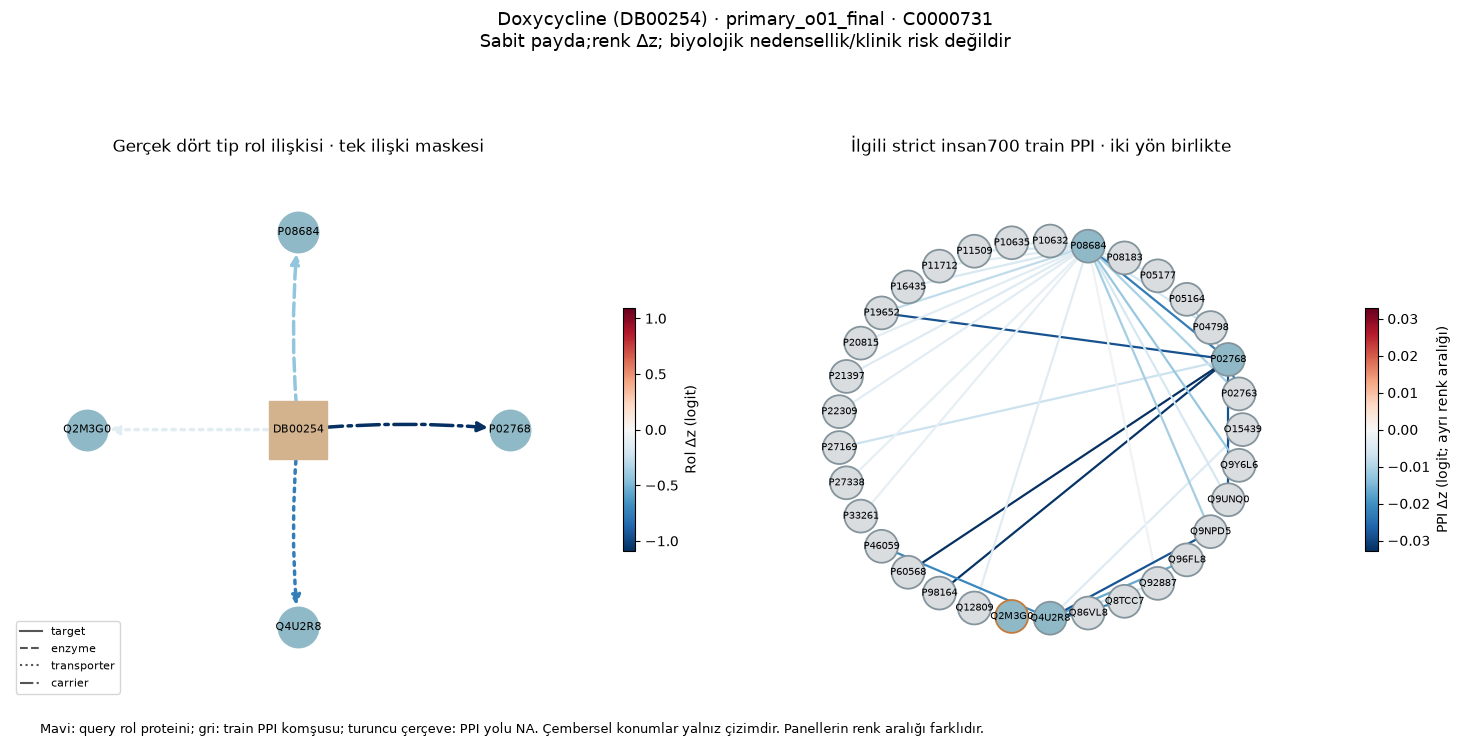

,role,protein_id,mode,original_logit,intervened_logit,delta_z,status
0,enzyme,P08684,fixed,-2.698212,-2.267407,-0.430804,OK
2,enzyme,P08684,delete,-2.698212,-2.306597,-0.391614,OK
4,transporter,Q2M3G0,fixed,-2.698212,-2.573262,-0.124949,OK
6,transporter,Q2M3G0,delete,-2.698212,-3.331203,0.632991,OK
8,transporter,Q4U2R8,fixed,-2.698212,-1.940272,-0.757940,OK
10,transporter,Q4U2R8,delete,-2.698212,-2.065221,-0.632991,OK
12,carrier,P02768,fixed,-2.698212,-1.608009,-1.090203,OK
14,carrier,P02768,delete,-2.698212,-1.616996,-1.081216,OK


In [4]:

import networkx as nx
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
examples=pd.read_csv(Q/'examples_frozen.csv');local=pd.read_csv(Q/'example_contributions.csv')
networks=json.loads((Q/'real_networks.json').read_text(encoding='utf-8'))
display(examples)
def real_network(net,filename):
    fig,axs=plt.subplots(1,2,figsize=(15,7.5))
    role_edges=[e for e in net['edges'] if e['kind']=='role'];ppi_edges=[e for e in net['edges'] if e['kind']=='ppi']
    role_nodes=sorted({e['target'] for e in role_edges});styles={'target':'solid','enzyme':'dashed','transporter':'dotted','carrier':'dashdot'}
    # Role panel shows exactly the observed typed drug–protein relations.
    drug=net['drug_id'];G=nx.MultiDiGraph();G.add_node(drug)
    for e in role_edges:G.add_edge(drug,e['target'],key=e['role'])
    pos={drug:np.array([0.,0.])}
    for i,n in enumerate(role_nodes):pos[n]=np.array([np.cos(2*np.pi*i/len(role_nodes)),np.sin(2*np.pi*i/len(role_nodes))])
    vmax=max([abs(e['delta_z']) for e in role_edges]+[1e-7]);norm=Normalize(-vmax,vmax);cmap=plt.get_cmap('RdBu_r')
    nx.draw_networkx_nodes(G,pos,nodelist=role_nodes,node_color='#90b9c7',node_size=850,ax=axs[0])
    nx.draw_networkx_nodes(G,pos,nodelist=[drug],node_color='#d3b38d',node_shape='s',node_size=1800,ax=axs[0])
    for i,e in enumerate(role_edges):nx.draw_networkx_edges(G,pos,edgelist=[(drug,e['target'],e['role'])],edge_color=[cmap(norm(e['delta_z']))],style=styles[e['role']],width=2.5,connectionstyle=f'arc3,rad={.05*(i%3-1)}',arrows=True,arrowsize=14,node_size=1000,ax=axs[0])
    nx.draw_networkx_labels(G,pos,font_size=8,ax=axs[0]);axs[0].set_title('Gerçek dört tip rol ilişkisi · tek ilişki maskesi')
    fig.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap),ax=axs[0],shrink=.45,label='Rol Δz (logit)')
    axs[0].legend(handles=[Line2D([0],[0],color='#555555',linestyle=style,label=r) for r,style in styles.items()],loc='lower left',fontsize=8)
    # PPI panel includes all incident train edges,NOT a highest-effect subgraph.
    H=nx.Graph();H.add_nodes_from(n['id'] for n in net['nodes'])
    H.add_edges_from((e['source'],e['target']) for e in ppi_edges)
    # Deterministic circular display avoids isolated nodes compressing the component.
    # All nodes/edges retained;positions have no biological meaning.
    pos2=nx.circular_layout(sorted(H))
    colors=['#90b9c7' if n in role_nodes else '#d9dde0' for n in H]
    nx.draw_networkx_nodes(H,pos2,node_size=560,node_color=colors,edgecolors=['#c47a3b' if H.degree(n)==0 else '#84949c' for n in H],linewidths=1.3,ax=axs[1])
    v=max([abs(e['delta_z']) for e in ppi_edges]+[1e-7]);norm2=Normalize(-v,v)
    nx.draw_networkx_edges(H,pos2,edgelist=[(e['source'],e['target']) for e in ppi_edges],edge_color=[cmap(norm2(e['delta_z'])) for e in ppi_edges],width=1.6,ax=axs[1])
    nx.draw_networkx_labels(H,pos2,font_size=7.2,ax=axs[1]);axs[1].set_title('İlgili strict insan700 train PPI · iki yön birlikte')
    fig.colorbar(plt.cm.ScalarMappable(norm=norm2,cmap=cmap),ax=axs[1],shrink=.45,label='PPI Δz (logit; ayrı renk aralığı)')
    for ax in axs:ax.set_axis_off();ax.margins(.15)
    fig.suptitle(f"{net['drug_name']} ({drug}) · {net['context']} · {net['class_id']}\nSabit payda;renk Δz; biyolojik nedensellik/klinik risk değildir",fontsize=13)
    fig.text(.03,.015,'Mavi: query rol proteini; gri: train PPI komşusu; turuncu çerçeve: PPI yolu NA. Çembersel konumlar yalnız çizimdir. Panellerin renk aralığı farklıdır.',fontsize=9)
    plt.tight_layout(rect=(0,.04,1,.91));plt.savefig(F/filename,dpi=160);plt.show()
    display(local[(local.context==net['context'])&(local.drug_id==drug)&(local.class_id==net['class_id'])&local.kind.eq('role')][['role','protein_id','mode','original_logit','intervened_logit','delta_z','status']])
real_network(networks[0],'02_Doxycycline_real_network.png')


**Grafik 2 — Ne öğrendik?** Doxycycline'in gerçek kaynak rol ilişkileri ve yalnız bu query'ye tek PPI katmanında ulaşabilen insan train kenarları gösterilir. Renk kaynak PT logitindeki değişimdir. Sağ panelin renk aralığı daha küçük olabilir; iki panelin renk doygunluğundan biyolojik büyüklük kıyası yapılmaz. İzole/bağlantısız rol proteini sıfır etkili PPI kenarı diye çizilmez.

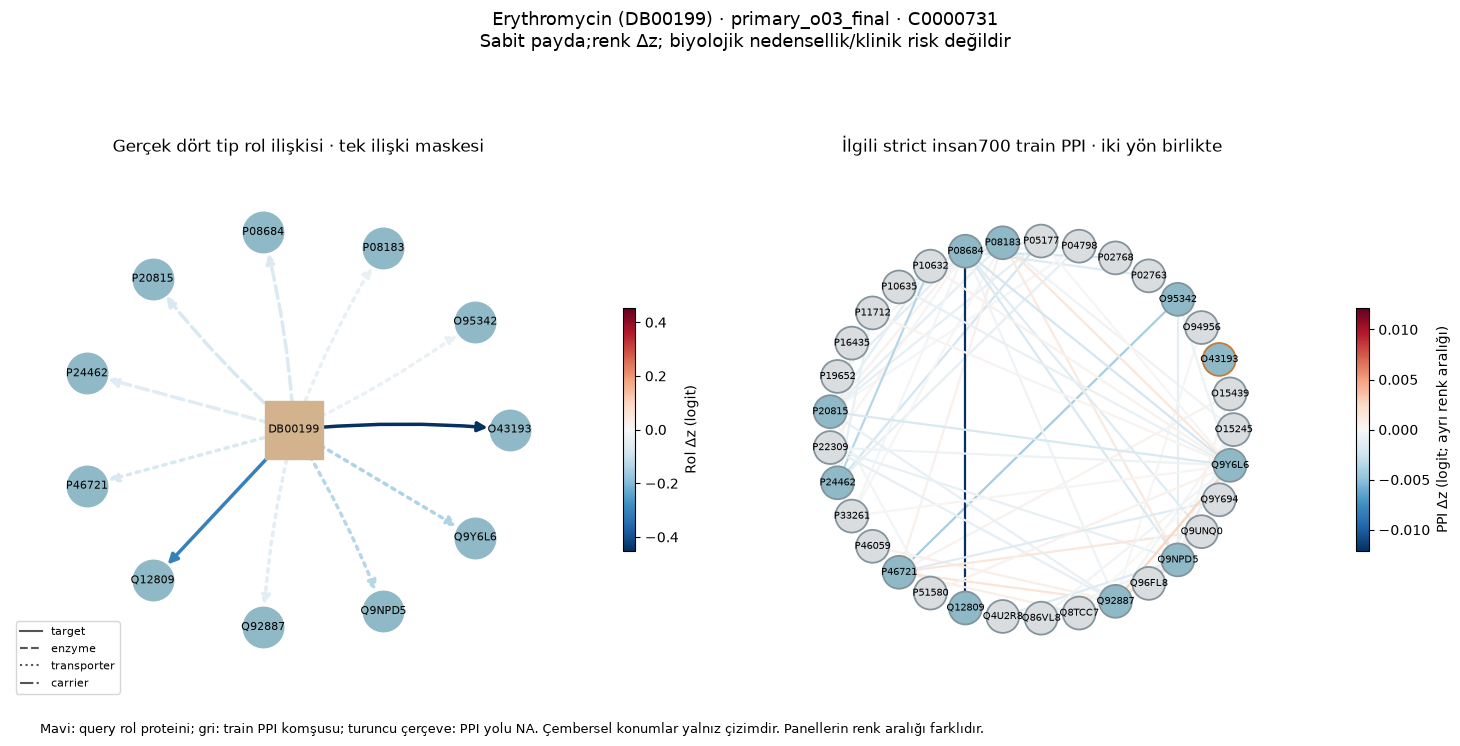

,role,protein_id,mode,original_logit,intervened_logit,delta_z,status
500,target,O43193,fixed,-1.768257,-1.316162,-0.452095,OK
502,target,O43193,delete,-1.768257,-1.620388,-0.147869,OK
504,target,Q12809,fixed,-1.768257,-1.464032,-0.304226,OK
506,target,Q12809,delete,-1.768257,-1.916127,0.147869,OK
508,enzyme,P08684,fixed,-1.768257,-1.704037,-0.064220,OK
510,enzyme,P08684,delete,-1.768257,-1.767135,-0.001123,OK
512,enzyme,P20815,fixed,-1.768257,-1.696893,-0.071364,OK
514,enzyme,P20815,delete,-1.768257,-1.756420,-0.011838,OK
516,enzyme,P24462,fixed,-1.768257,-1.713426,-0.054832,OK
518,enzyme,P24462,delete,-1.768257,-1.781218,0.012961,OK


In [5]:

real_network(networks[1],'03_Erythromycin_real_network.png')


**Grafik 3 — Ne öğrendik?** Erythromycin kendi primary outer3 modelinde heldout query'dir. 11 rol ilişkisi ayrı türleriyle korunur; bu örnekte çizilen 85 PPI bağı gerçek train kapsamından gelir. Tekil kenarın Δz değeri tüm rolün/proteinin ortak nedensel etkisi değildir. Paylaşılan protein/PPI yolları ve ReLU nedeniyle kenar katkıları toplamı bütün model farkı sayılmaz.

## 4. Düşük katkılar, gerçek sıfırlar ve dört ayrı rol

,protocol,kind,mode,interventions,finite_interventions,NA_interventions,native_PT_pair_count,mean_of_native_PT_mean_abs_delta,median_of_native_PT_mean_abs_delta,max_abs_delta_any_PT,near_zero_PT_pairs_abs_tol_1e7
0,primary,ppi,delete,1623,1623,0,477592,0.003533,0.001755,0.183439,24
1,primary,ppi,fixed,1623,1623,0,477592,0.006473,0.003483,0.226798,10
2,primary,role,delete,476,476,0,139060,0.111530,0.036519,3.066543,0
3,primary,role,fixed,476,476,0,139060,0.173636,0.109408,3.014943,0
4,stress,ppi,delete,1604,1604,0,464109,0.004032,0.001982,0.258389,15
5,stress,ppi,fixed,1604,1604,0,464109,0.007744,0.004263,0.279962,7
6,stress,role,delete,476,476,0,139727,0.122221,0.040407,3.667000,0
7,stress,role,fixed,476,476,0,139727,0.186299,0.115206,3.692886,0


,kind,rows,max_delta_identity_roundtrip_error,NA_rows,exact_zero_delta_rows,abs_delta_at_most_1e7_rows,native_PT_scope_only
0,role,557574,4.690000e-07,0,0,0,True
1,ppi,1883402,4.700000e-07,0,48,56,True


,protocol,role,ilişki,ortalama_native_PT_mutlak_delta,medyan_native_PT_mutlak_delta
0,primary,carrier,22,0.373439,0.420266
1,primary,enzyme,78,0.150721,0.093678
2,primary,target,241,0.143061,0.089931
3,primary,transporter,135,0.208896,0.143217
4,stress,carrier,22,0.301131,0.348853
5,stress,enzyme,78,0.170074,0.118097
6,stress,target,241,0.157347,0.090042
7,stress,transporter,135,0.228644,0.161026


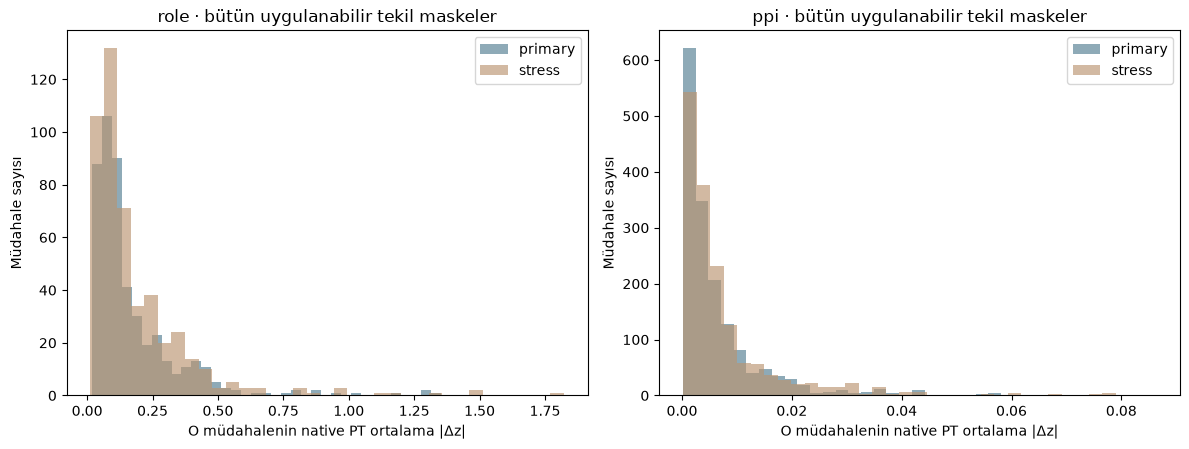

In [6]:

desc=pd.read_csv(Q/'descriptive_summary.csv');interventions=pd.read_csv(Q/'intervention_summary.csv')
display(desc);display(pd.read_csv(Q/'compressed_table_stream_checks.csv'))
role_stats=interventions[interventions.kind.eq('role')&interventions['mode'].eq('fixed')].groupby(['protocol','role']).agg(ilişki=('status','size'),ortalama_native_PT_mutlak_delta=('mean_abs_delta','mean'),medyan_native_PT_mutlak_delta=('mean_abs_delta','median')).reset_index();display(role_stats)
fig,axs=plt.subplots(1,2,figsize=(12,4.6))
for ax,kind in zip(axs,['role','ppi']):
    for p,color in [('primary','#527d91'),('stress','#ba9470')]:
        d=interventions[interventions.kind.eq(kind)&interventions.protocol.eq(p)&interventions['mode'].eq('fixed')]
        ax.hist(d.mean_abs_delta,bins=35,alpha=.65,label=p,color=color)
    ax.set(title=kind+' · bütün uygulanabilir tekil maskeler',xlabel='O müdahalenin native PT ortalama |Δz|',ylabel='Müdahale sayısı');ax.legend()
plt.tight_layout();plt.savefig(F/'04_real_delta_distributions.png',dpi=160);plt.show()


**Grafik 4 — Ne öğrendik?** Primary sabit-maskede müdahale başına native-PT mean |Δz| ortalaması rol ilişkilerinde 0,173636, PPI'da 0,006473 logittir; stres değerleri 0,186299 ve 0,007744'tür. Bu, farklı PT sözlüklerini ve farklı müdahale nesnelerini içeren betimsel özettir; ortak global SHAP, klinik etki veya performans ölçüsü değildir.

İki yöntem/protokol birlikte PPI tablolarında 48 tam sıfır ve |Δz|≤10⁻⁷ olan 56 satır korunmuştur. Bunlar **mevcut, uygulanabilir** kenarlardır. NA yollar tabloda ayrı saklanır; bu sıfırlara katılmaz. Tekrar edilen çiftler bağımsız biyolojik gözlem değildir.

## 5. Fiziksel silme neden ayrı bir duyarlılıktır?

,kind,context,drug_id,role,protein_id,protein_a,protein_b,mean_abs_delta_fixed,mean_abs_delta_delete,mean_abs_delta_delete_minus_fixed
0,role,primary_o01_final,DB00254,enzyme,P08684,NaN,NaN,0.307799,0.328275,0.020476
1,role,primary_o01_final,DB00254,transporter,Q2M3G0,NaN,NaN,0.076088,0.344841,0.268753
2,role,primary_o01_final,DB00254,transporter,Q4U2R8,NaN,NaN,0.408434,0.344841,-0.063594
3,role,primary_o01_final,DB00254,carrier,P02768,NaN,NaN,0.508152,0.522097,0.013945
4,role,primary_o01_final,DB00438,target,P02918,NaN,NaN,0.062482,0.022403,-0.040079
5,role,primary_o01_final,DB00438,target,P02919,NaN,NaN,0.048940,0.030183,-0.018757
6,role,primary_o01_final,DB00438,target,P0AD65,NaN,NaN,0.039857,0.039122,-0.000735
7,role,primary_o01_final,DB00438,target,P0AD68,NaN,NaN,0.104698,0.046212,-0.058485
8,role,primary_o01_final,DB00438,target,Q47066,NaN,NaN,0.098481,0.038565,-0.059917
9,role,primary_o01_final,DB00438,transporter,Q4U2R8,NaN,NaN,0.816869,0.835543,0.018674


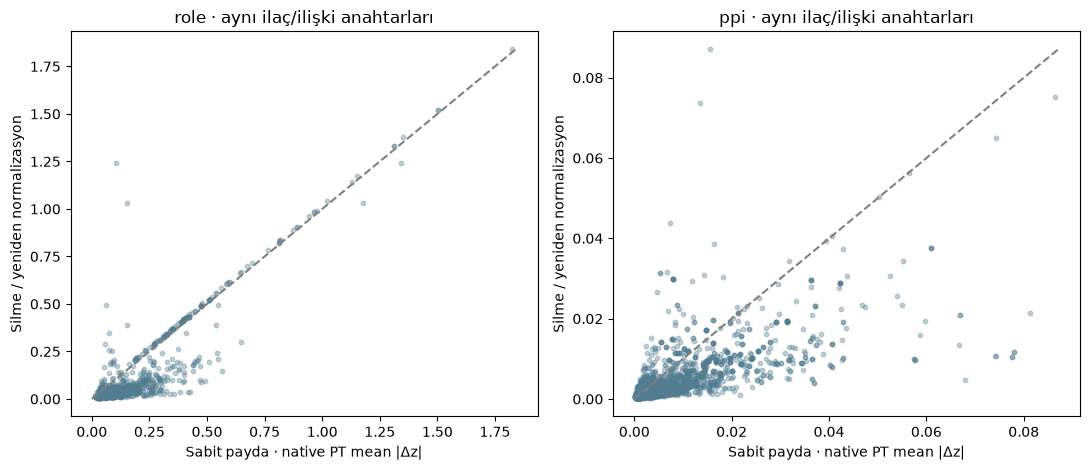

In [7]:

paired=pd.read_csv(Q/'mask_vs_deletion_sensitivity.csv');display(paired[['kind','context','drug_id','role','protein_id','protein_a','protein_b','mean_abs_delta_fixed','mean_abs_delta_delete','mean_abs_delta_delete_minus_fixed']].head(20))
fig,axs=plt.subplots(1,2,figsize=(11,4.8))
for ax,kind in zip(axs,['role','ppi']):
    d=paired[paired.kind.eq(kind)];ax.scatter(d.mean_abs_delta_fixed,d.mean_abs_delta_delete,s=10,alpha=.35,color='#527d91')
    high=max(d.mean_abs_delta_fixed.max(),d.mean_abs_delta_delete.max());ax.plot([0,high],[0,high],color='gray',linestyle='--')
    ax.set(title=kind+' · aynı ilaç/ilişki anahtarları',xlabel='Sabit payda · native PT mean |Δz|',ylabel='Silme / yeniden normalizasyon')
plt.tight_layout();plt.savefig(F/'05_mask_vs_deletion.png',dpi=160);plt.show()


**Grafik 5 — Ne öğrendik?** Aynı ilişki için maske ve fiziksel silme aynı soru değildir. Sabit payda toplam mesajı azaltır; silme kalan komşuların ağırlığını yeniden düzenler. Son rol ilişkisinin silinmesinde availability maskesi de değişir. Gerçek veride müdahale sonrası yeni abstention oluşmadı; bu olasılık analitik testte doğrulandı. İki yöntemin farklılaşması tek başına hesap hatası veya istikrarsız model kanıtı değildir.

## 6. Sayısal kararlılık ve query/cache izolasyonu

,context,check,max_abs_logit_error
0,primary_o01_final,query_order_role_mask,0.000000e+00
1,primary_o01_final,query_alone_role_mask,1.192093e-06
2,primary_o01_final,protein_index_permutation_no_mask,4.768372e-07
3,primary_o01_final,protein_permutation_PPI_mask_reverse_endpoint_ID,4.768372e-07
4,primary_o02_final,query_order_role_mask,0.000000e+00
5,primary_o02_final,query_alone_role_mask,4.768372e-07
6,primary_o02_final,protein_index_permutation_no_mask,4.768372e-07
7,primary_o02_final,protein_permutation_PPI_mask_reverse_endpoint_ID,4.768372e-07
8,primary_o03_final,query_order_role_mask,0.000000e+00
9,primary_o03_final,query_alone_role_mask,9.536743e-07


,context,check,max_abs_error
0,primary_o01_final,edge_order_PPI_delta_z,4.768372e-07
1,primary_o01_final,edge_order_role_delta_z,9.536743e-07
2,primary_o01_final,query_alone_role_delta_z,7.152557e-07
3,primary_o02_final,edge_order_PPI_delta_z,0.000000e+00
4,primary_o02_final,edge_order_role_delta_z,2.384186e-07
5,primary_o02_final,query_alone_role_delta_z,5.960464e-07
6,primary_o03_final,edge_order_PPI_delta_z,0.000000e+00
7,primary_o03_final,edge_order_role_delta_z,3.576279e-07
8,primary_o03_final,query_alone_role_delta_z,1.072884e-06
9,primary_o04_final,edge_order_PPI_delta_z,2.384186e-07


,context,reference_logit_error,original_cache_error,OOF_score_error,OOF_pairs_checked,role_interventions,PPI_query_interventions,repeat_error,other_query_role_isolation_error,delete_NA_interventions,model_graph_query_cache_unchanged
0,primary_o01_final,0.0,0.0,1.110223e-16,3120,122,406,0.0,0.0,0,True
1,primary_o02_final,0.0,0.0,5.960464e-08,3718,99,284,0.0,0.0,0,True
2,primary_o03_final,0.0,0.0,2.980232e-08,3498,78,397,0.0,0.0,0,True
3,primary_o04_final,0.0,0.0,5.960464e-08,3756,80,158,0.0,0.0,0,True
4,primary_o05_final,0.0,0.0,1.490116e-08,3912,97,378,0.0,0.0,0,True
5,stress_o01_final,0.0,0.0,2.980232e-08,3822,117,333,0.0,0.0,0,True
6,stress_o02_final,0.0,0.0,1.110223e-16,3952,120,330,0.0,0.0,0,True
7,stress_o03_final,0.0,0.0,1.490116e-08,3912,71,228,0.0,0.0,0,True
8,stress_o04_final,0.0,0.0,1.110223e-16,3344,77,286,0.0,0.0,0,True
9,stress_o05_final,0.0,0.0,2.980232e-08,2940,91,427,0.0,0.0,0,True


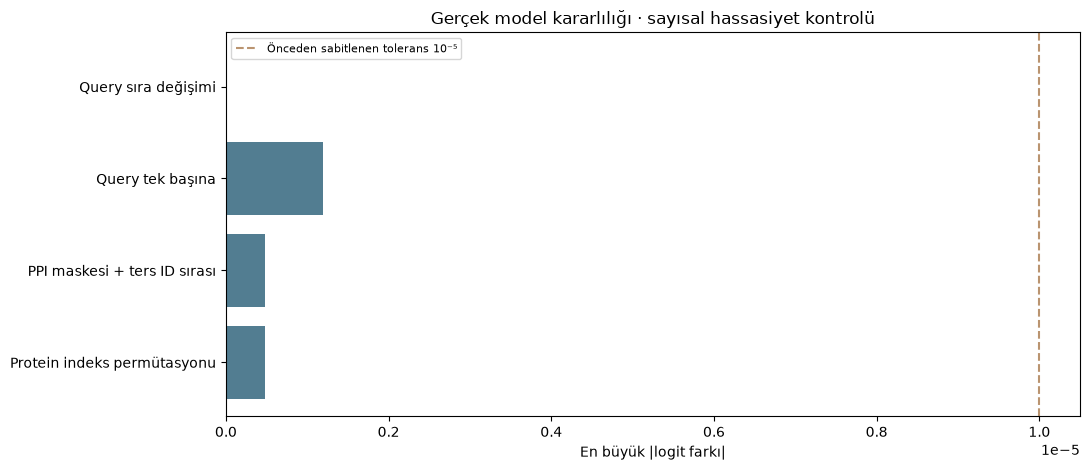

In [8]:

stability=pd.read_csv(Q/'stability_checks.csv');display(stability)
display(pd.read_csv(Q/'additional_delta_stability.csv'))
consistency=pd.read_csv(Q/'consistency_checks.csv');display(consistency)
d=stability.groupby('check').max_abs_logit_error.max()
fig,ax=plt.subplots(figsize=(11,4.8));ax.barh(['Protein indeks permütasyonu','PPI maskesi + ters ID sırası','Query tek başına','Query sıra değişimi'],d.reindex(['protein_index_permutation_no_mask','protein_permutation_PPI_mask_reverse_endpoint_ID','query_alone_role_mask','query_order_role_mask']),color='#527d91')
ax.axvline(1e-5,color='#ba9470',linestyle='--',label='Önceden sabitlenen tolerans 10⁻⁵');ax.set(xlabel='En büyük |logit farkı|',title='Gerçek model kararlılığı · sayısal hassasiyet kontrolü');ax.legend(fontsize=8)
plt.tight_layout();plt.savefig(F/'06_numeric_stability.png',dpi=160);plt.show()


**Grafik 6 — Ne öğrendik?** Bütün tekil müdahaleler tekrar hesaplandı; fark sıfırdı. On bağlamın ilk gerçek ilişki/kenarında query sırası, query tek başına, protein indeks permütasyonu ve ters endpoint ID kontrolleri yapıldı. Grafikteki en büyük fark 1,192×10⁻⁶ logittir. Ek30 kontrolde yalnız kenar sırasını değiştirme ve query'yi tek başına kullanma için doğrudan Δz farkı da ölçüldü; en büyük fark 1,550×10⁻⁶ oldu. Her ikisi dondurulmuş float32 toleransının altındadır. Bu, bootstrap CI veya biyolojik stabilite değildir; yalnız sabit modelde uygulama/sayısal kararlılıktır.

Rol maskesi diğer query skorlarını değiştirmedi. PPI müdahalesi kopya bir cache üretti; orijinal train cache, kaynak graph/query ve model digest'leri değişmedi. Kaynakta olmayan self-only query proteinlerine PPI eklenmedi.

## 7. Testler, veri güvenliği ve durma noktası

In [9]:

print((Q/'real_tests_v1.txt').read_text(encoding='utf-8'))
display(pd.DataFrame([complete]).T.rename(columns={0:'sonuç'}))
print('Ayrıntılı rapor:',ROOT/'reports/WP11_GRAPH_EXPLANATIONS.md')
print('İlk teknik hata arşivi:',Q/'attempt_01_technical_failure')


test_01_policy_and_source_hashes (test_wp11_graph_real.RealGraphTests.test_01_policy_and_source_hashes) ... ok
test_02_all_accepted_artifacts_including_B1 (test_wp11_graph_real.RealGraphTests.test_02_all_accepted_artifacts_including_B1) ... ok
test_03_synthetic_gate_preceded_real_attribution (test_wp11_graph_real.RealGraphTests.test_03_synthetic_gate_preceded_real_attribution) ... ok
test_04_all10_reference_and_OOF_reconstruction (test_wp11_graph_real.RealGraphTests.test_04_all10_reference_and_OOF_reconstruction) ... ok
test_05_real_role_mask_analytic_head_delta (test_wp11_graph_real.RealGraphTests.test_05_real_role_mask_analytic_head_delta) ... ok
test_06_real_query_model_graph_cache_immutable (test_wp11_graph_real.RealGraphTests.test_06_real_query_model_graph_cache_immutable) ... ok
test_07_actual_ID_resolution_and_two_way_mask (test_wp11_graph_real.RealGraphTests.test_07_actual_ID_resolution_and_two_way_mask) ... ok
test_08_all62_inventory61eligible_and_NA_preserved (test_wp11_graph

,sonuç
status,PASS
models,10
all_original_outputs,35974
contribution_rows,"{'role': 557574, 'ppi': 1883402}"
prior_files_preserved,3079
synthetic_tests_first,True
guarded_fit_optimizer_backward_calls,0
WP11_final_closed,False
WP12,False
new_training,False


**Sınır:** Önce 10 sentetik, ardından 16 gerçek-model testi geçti. 557.574 rol ve 1.883.402 PPI satırı iki yöntemi/protokolü ve kendi fit edilmiş PT başlıklarını içerir. Büyük tablolar gzip CSV olarak akışla yazılıp kontrol edildi. Eksik PT hedefi birleştirilmedi veya doldurulmadı; protein/kenar açıklaması B1 SHAP ile eşdeğer sayılmadı.

Bu gözlemler WP09/WP10'da gösterilememiş PPI performans üstünlüğünü değiştirmez. Protein biyolojisinin genel olarak yararsızlığı da çıkarılamaz. 62/1061/6416,54/8 QC,Methenamine/Tobramycin ve 1.685 kapsam dışı kaynak pozitif sınırı korunur. Yeni eğitim, optimizer veya model araması yapılmadı. **Graf açıklaması uygulaması tamamlandı; WP11 nihai kapanışı yapılmadı. Kullanıcı değerlendirmesi bekleniyor; WP12 başlamadı.**